# Catapult model: corrected reference

This notebook replaces `Ambassador project/Model.ipynb` as the reference implementation. The physics lives in
[`catapult_model.py`](catapult_model.py) so the notebook, the tests and the fixture generator for the web tool all use the
same code. Each section below addresses one finding of the model review.

Conventions (see the schematic `drawing.svg`): every angle is the angle of the throwing arm from the vertical,
which equals the angle between the foot and the spring arm. The arm swings from $\theta_i$ (pull-back) to
$\theta_f$ (stop); the ball leaves perpendicular to the arm, so its launch elevation is $\theta_f$.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

import catapult_model as cm

base = cm.CatapultParams()
base

CatapultParams(l_left=0.05, l_right=0.05, l_foot=0.03, pivot_height=0.08, theta_i=2.0943951023931953, theta_f=0.5235987755982988, k=100.0, l0=0.0, inertia=1.5e-05, mass=0.01, efficiency=1.0, drag_model='none', drag=0.0, release_offset=0.0, g=9.81)

## 1. Energy bug: $I/L_\text{left}^2$, not `I/Lleft*2`

$$\tfrac12 I\omega^2 + \tfrac12 m v^2 = \tfrac12\left(\frac{I}{L_\text{left}^2} + m\right)v_0^2, \qquad v_0 = \omega L_\text{left}$$

With the original notebook values the bug made the effective mass almost 10× too small.

In [2]:
nb = cm.CatapultParams(theta_i=3 * math.pi / 4, theta_f=math.pi / 6, inertia=1e-3, pivot_height=0.03)
buggy_meff = nb.inertia / nb.l_left * 2 + nb.mass
v_buggy = math.sqrt(2 * cm.released_energy(nb) / buggy_meff)
print(f"effective mass: buggy {buggy_meff:.3f} kg, correct {cm.effective_mass(nb):.3f} kg")
print(f"launch speed:   buggy {v_buggy:.2f} m/s, correct {cm.launch_speed(nb):.2f} m/s")

effective mass: buggy 0.050 kg, correct 0.410 kg
launch speed:   buggy 3.07 m/s, correct 1.07 m/s


## 2. A realistic moment of inertia

$I = 10^{-3}$ kg m² would be a 10 cm rod of about 1.2 kg. For a printed arm of ~10 g with a ~3 g cup the inertia is
about $1.6\times10^{-5}$ kg m², i.e. the arm "weighs" like ~6 g at the cup, comparable to the 10 g ball. Weigh your
own printed arm and use `rod_inertia`:

In [3]:
I = cm.rod_inertia(rod_mass=0.010, l_left=0.05, l_right=0.05, cup_mass=0.003)
print(f"I = {I:.2e} kg m^2  ->  I / L_left^2 = {I / 0.05**2 * 1000:.1f} g")

I = 1.58e-05 kg m^2  ->  I / L_left^2 = 6.3 g


## 3. Drag with consistent units, and quadratic drag as "model v2"

The notebook used $\dot v = -\gamma v$ with $\gamma$ labelled N s/m, but then $\gamma$ is really a rate in 1/s.
The reference model takes force coefficients and divides by the mass:

* linear: $m\dot{\vec v} = -b\,\vec v - m g\hat y$, $b$ in N s/m
* quadratic: $m\dot{\vec v} = -c\,|\vec v|\,\vec v - m g\hat y$, $c = \tfrac12\rho C_d A$ in kg/m

For a 2 cm ball $c \approx 0.5 \cdot 1.2 \cdot 0.47 \cdot \pi (0.01)^2 \approx 9\times10^{-5}$ kg/m. At catapult speeds
drag changes the range by only a few percent, which is itself a useful lesson.

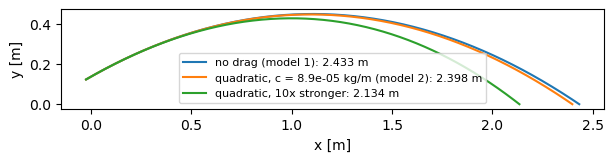

In [4]:
c_ball = 0.5 * 1.2 * 0.47 * math.pi * 0.01**2
fig, ax = plt.subplots(figsize=(7, 3))
for label, p in [
    ("no drag (model 1)", base),
    (f"quadratic, c = {c_ball:.1e} kg/m (model 2)", base.with_(drag_model="quadratic", drag=c_ball)),
    ("quadratic, 10x stronger", base.with_(drag_model="quadratic", drag=10 * c_ball)),
]:
    _, x_land, traj = cm.simulate(p)
    ax.plot(traj[:, 0], traj[:, 1], label=f"{label}: {x_land:.3f} m")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_aspect("equal"); ax.legend(fontsize=8)
plt.show()

## 4. Landing point: event detection instead of `np.interp`

`np.interp` needs increasing x-values, but on the way down $y$ decreases. The reference uses `solve_ivp` with a
terminal event at $y = 0$. Below, the original `throw_length` approach is compared with the event-based range.

In [5]:
def throw_length_original(p):
    # The notebook's method: fixed time grid, keep points with |y| < 2.5 cm, np.interp on y.
    s0 = cm.launch_state(p)
    v0 = cm.launch_speed(p)
    gam = p.drag / p.mass if p.drag_model == "linear" else 0.0
    dsdt = lambda s, t: (s[2], s[3], -gam * s[2], -gam * s[3] - p.g)
    tmax = (v0 / p.g + np.sqrt(2 * (v0**2 / p.g + s0[1]) / p.g)) * 1.1
    sol = odeint(dsdt, s0, np.linspace(0, tmax, 1000))
    mask = (sol[:, 1] < 0.025) * (sol[:, 1] > -0.025)
    return np.interp(0, sol[mask, 1], sol[mask, 0])

for th_f in (15, 30, 45, 60):
    p = base.with_(theta_f=math.radians(th_f), drag_model="linear", drag=2e-3)
    old, new = throw_length_original(p), cm.throw_range(p)
    print(f"theta_f = {th_f:2d} deg: interp {old:.3f} m, event {new:.3f} m  ({(old - new) / new:+.1%})")

theta_f = 15 deg: interp 1.752 m, event 1.699 m  (+3.2%)
theta_f = 30 deg: interp 2.303 m, event 2.272 m  (+1.4%)
theta_f = 45 deg: interp 2.195 m, event 2.177 m  (+0.9%)
theta_f = 60 deg: interp 1.522 m, event 1.510 m  (+0.8%)


## 5. Labels and angle convention

The spring constant is in **N/m** (the original axis said N/s). The angle convention was checked against
`drawing.svg`: $\theta$ is measured between the foot and the spring arm, the cup sits at
$(-L_\text{left}\sin\theta, h + L_\text{left}\cos\theta)$ and the release velocity
$v_0(\cos\theta_f, \sin\theta_f)$ is perpendicular to the arm. The drawing also shows that the spring anchor
(bottom of $L_\text{foot}$) is not the floor, so the model has a separate pivot height $h$.

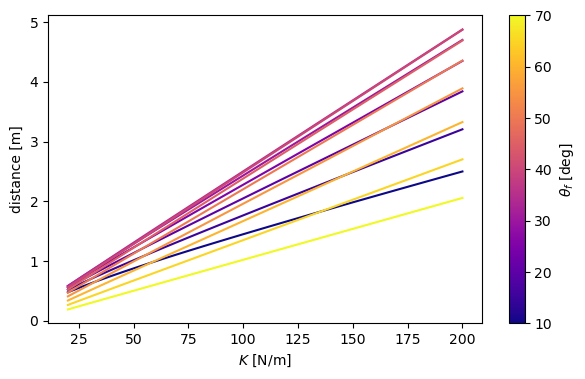

In [6]:
Ks = np.linspace(20, 200, 30)
thfs = np.radians(np.linspace(10, 70, 13))
norm = plt.Normalize(np.degrees(thfs.min()), np.degrees(thfs.max()))
fig, ax = plt.subplots(figsize=(7, 4))
for th_f in thfs:
    ranges = [cm.throw_range(base.with_(k=K, theta_f=th_f)) for K in Ks]
    ax.plot(Ks, ranges, color=plt.cm.plasma(norm(np.degrees(th_f))))
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="plasma"), ax=ax, label=r"$\theta_f$ [deg]")
ax.set_xlabel("$K$ [N/m]"); ax.set_ylabel("distance [m]")
plt.show()

## 6. Spring rest length

A real spring or rubber band has a rest length $l_0$ (and a band cannot push when slack):

$$\Delta E = \tfrac12 K\left[(l_i - l_0)^2 - (l_f - l_0)^2\right]$$

With $l_0 = 0$ this reduces to the notebook's $K L_\text{foot} L_\text{right}(\cos\theta_i - \cos\theta_f)$
(up to sign).

In [7]:
for l0 in (0.0, 0.01, 0.02, 0.03):
    p = base.with_(l0=l0)
    print(f"l0 = {l0 * 100:.0f} cm: energy {cm.released_energy(p) * 1000:6.1f} mJ, range {cm.throw_range(p):.2f} m")

l0 = 0 cm: energy  204.9 mJ, range 2.43 m
l0 = 1 cm: energy  163.2 mJ, range 1.97 m
l0 = 2 cm: energy  121.5 mJ, range 1.50 m
l0 = 3 cm: energy   80.0 mJ, range 1.04 m


## Design note: parameter degeneracy

The launch speed depends only on $\eta\,\Delta E / m_\text{eff}$. Doubling $K$ and halving the efficiency gives
exactly the same range, so $K$, $I$, $m$ and $\eta$ cannot be fitted separately from distance data. The web tool
therefore fixes the measured quantities and lets students tune only the efficiency (plus drag and a release-angle
correction).

In [8]:
a = base.with_(k=100, efficiency=0.8)
b = base.with_(k=200, efficiency=0.4)
print(cm.throw_range(a), cm.throw_range(b))

1.9768647274749866 1.9768647274749866
